In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
# file is actually a ZIP (Kaggle download), read it directly
df = pd.read_csv('netflix_titles.csv', compression='zip')
display(df.head())

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [23]:
print(df.shape)
df.info()
print(df.isnull().sum())

(8807, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
descriptio

In [24]:
# Fill missing values
df['director'].fillna('Unknown', inplace=True)
df['cast'].fillna('Unknown', inplace=True)
df['country'].fillna('Unknown', inplace=True)
df['rating'].fillna('Not Rated', inplace=True)

# Extract year from date_added
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
df['year_added'] = df['date_added'].dt.year

print("Cleaning done. Nulls remaining:")
print(df.isnull().sum())

Cleaning done. Nulls remaining:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           0
duration         3
listed_in        0
description      0
year_added      98
dtype: int64


/tmp/ipykernel_739/781486210.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['director'].fillna('Unknown', inplace=True)
/tmp/ipykernel_739/781486210.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 

/tmp/ipykernel_739/4106451953.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette=['#333333', '#999999'])


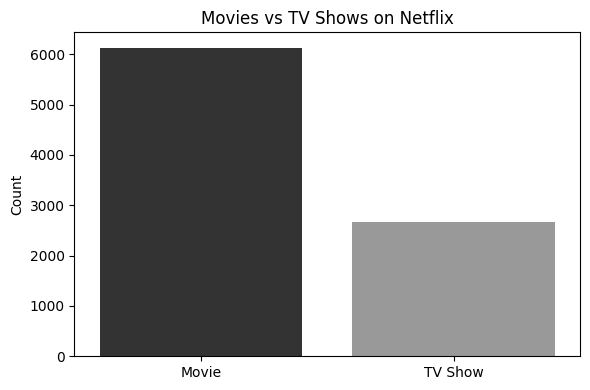

In [25]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='type', palette=['#333333', '#999999'])
plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

/tmp/ipykernel_739/2683995546.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='Greys_r')


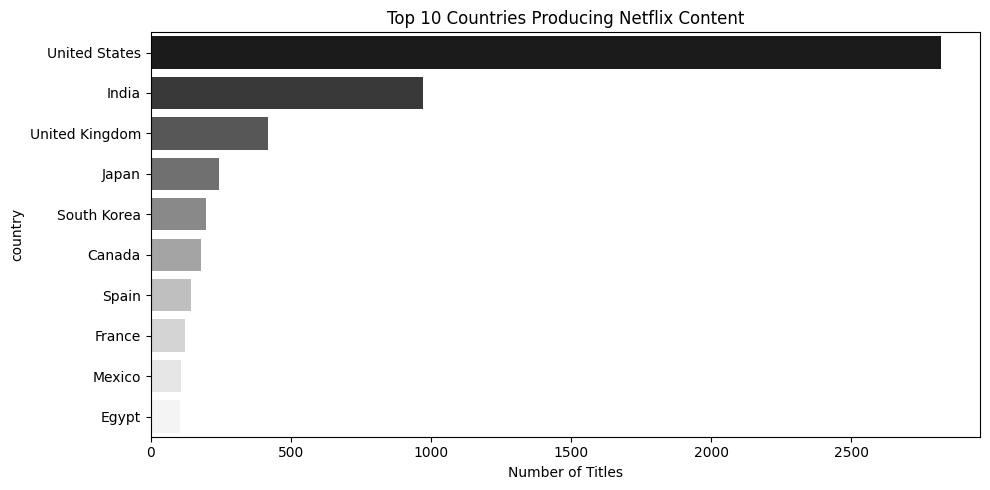

In [26]:
top_countries = df[df['country'] != 'Unknown']['country'].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='Greys_r')
plt.title('Top 10 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.show()

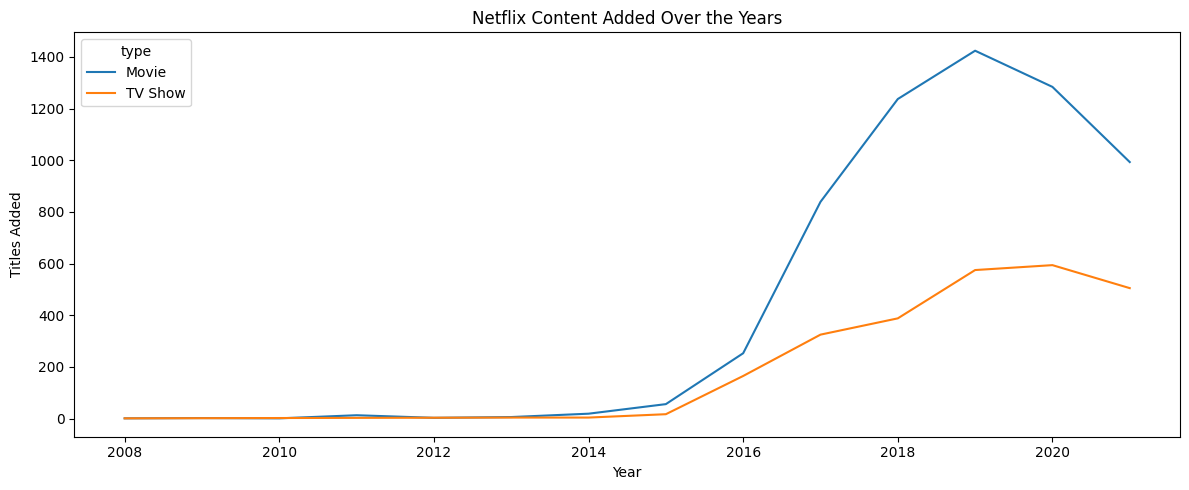

In [27]:
yearly = df.groupby(['year_added','type']).size().reset_index(name='count')

plt.figure(figsize=(12,5))
sns.lineplot(data=yearly, x='year_added', y='count', hue='type')
plt.title('Netflix Content Added Over the Years')
plt.xlabel('Year')
plt.ylabel('Titles Added')
plt.tight_layout()
plt.show()

/tmp/ipykernel_739/778762833.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette='Greys_r')


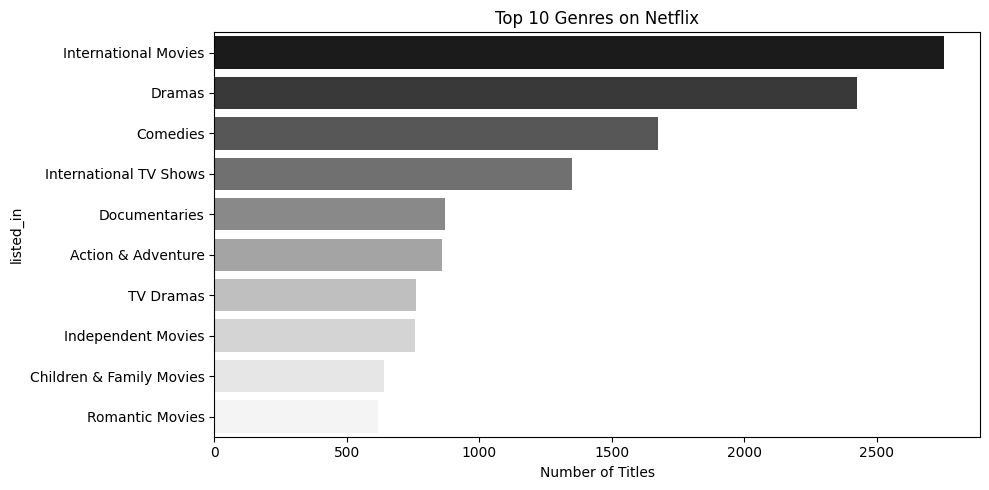

In [28]:
from collections import Counter

genres = df['listed_in'].str.split(', ').explode()
top_genres = genres.value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_genres.values, y=top_genres.index, palette='Greys_r')
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.tight_layout()
plt.show()

/tmp/ipykernel_739/2775071783.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rating', order=rating_order, palette='Greys_r')


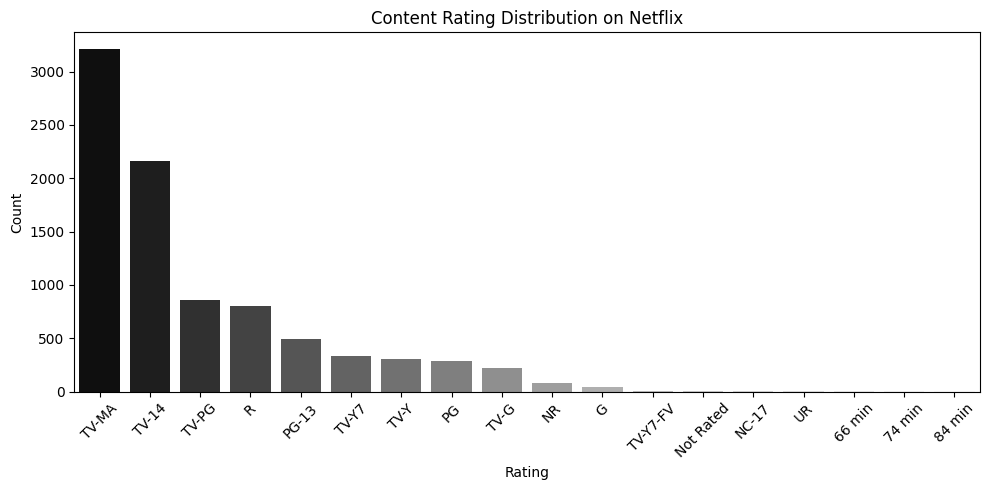

In [29]:
rating_order = df['rating'].value_counts().index.tolist()

plt.figure(figsize=(10,5))
sns.countplot(data=df, x='rating', order=rating_order, palette='Greys_r')
plt.title('Content Rating Distribution on Netflix')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
movies = df[df['type'] == 'Movie'].shape[0]
shows = df[df['type'] == 'TV Show'].shape[0]
top_country = df[df['country'] != 'Unknown']['country'].value_counts().index[0]
top_genre = genres.value_counts().index[0]
peak_year = df.groupby('year_added').size().idxmax()
top_rating = df['rating'].value_counts().index[0]

print("=" * 45)
print("   NETFLIX CONTENT ANALYSIS — KEY FINDINGS")
print("=" * 45)
print(f"Total Titles Analyzed  : {df.shape[0]:,}")
print(f"Movies                 : {movies:,}")
print(f"TV Shows               : {shows:,}")
print(f"Top Country            : {top_country}")
print(f"Top Genre              : {top_genre}")
print(f"Peak Year (content added): {int(peak_year)}")
print(f"Most Common Rating     : {top_rating}")
print("=" * 45)

   NETFLIX CONTENT ANALYSIS — KEY FINDINGS
Total Titles Analyzed  : 8,807
Movies                 : 6,131
TV Shows               : 2,676
Top Country            : United States
Top Genre              : International Movies
Peak Year (content added): 2019
Most Common Rating     : TV-MA
